## 전처리 노트북입니다

In [1]:
# 모듈 임포트 셀
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
plt.rcParams["font.family"] = "AppleGothic" # 한글 깨짐 방지
plt.rcParams["axes.unicode_minus"] = False

In [3]:
# 데이터 불러오기
df = pd.read_csv("../data/raw/신용보증기금_법인기업_금융생산성자료.csv", encoding="utf-8")
print(df.shape)
df.head()

(13389, 38)


,설립연도,최종업종코드,최종업종차수,업종명,기업규모,상장등록법인,지번주소,24년 총자산,24년 부채,24년 자기자본,...,21년 차입금회전율,21년 부가가치율,21년 총자산회전율,20년 총자산,20년 부채,20년 자기자본,20년 차입금회전율,20년 부가가치율,20년 총자산회전율,3개년 매출액증가여부
0,2005,C24***,11,"기타 비철금속 제련, 정련 및 합금 제조업",소기업,기타,인천 남동구,40억미만,20억미만,30억미만,...,12.30,NaN,0.79,50억미만,20억미만,30억미만,6.88,8.62,1.19,부
1,1997,F42***,11,콘크리트 및 철근 공사업,중기업,기타,경기도 안양시,120억미만,70억미만,60억미만,...,8.17,NaN,0.39,100억미만,60억미만,40억미만,13.00,17.30,0.29,부
2,2005,G46***,11,"골재, 벽돌 및 시멘트 도매업",소기업,기타,인천 남동구,120억미만,70억미만,50억미만,...,1.89,NaN,0.94,100억미만,60억미만,40억미만,1.73,NaN,1.13,여
3,2004,C28***,11,"전기회로 개폐, 보호장치 제조업",중기업,기타,경기도 성남시,180억미만,120억미만,60억미만,...,3.03,NaN,0.78,120억미만,70억미만,50억미만,3.56,NaN,0.78,여
4,2001,F42***,11,배관 및 냉ㆍ난방 공사업,소기업,기타,경기도 성남시,20억미만,10억미만,10억미만,...,69.00,NaN,0.54,20억미만,10억미만,20억미만,20.10,NaN,0.75,부


In [4]:
# 억 미만 제거
# 억 미만을 빈 문자열으로 replace
# 10억 사이의 중앙값을 취함

def bucket(text):
    if not isinstance(text, str):
        return text
    return int(text.replace("억미만", "")) - 5

money_cols = ["총자산", "부채", "자기자본"]
years = [20,21,22,23,24]
for i in years :
    for j in money_cols : 
        col = str(i) + "년 " + j
        df[col] = df[col].apply(bucket)
        if j == "부채":
            df[col] = df[col].clip(lower=0) # 부채는 음수가 될 수 없음
        if j == "총자산":
            df[col] = df[col].where(df[col] > 0) # 총자산 0 이하는 결측 처리

df[["24년 총자산", "24년 부채", "24년 자기자본"]].describe()

,24년 총자산,24년 부채,24년 자기자본
count,13389.000000,13389.000000,13389.000000
mean,151.171484,93.082754,58.528269
std,1527.048433,1228.022174,425.230857
min,5.000000,5.000000,-5375.000000
25%,25.000000,15.000000,5.000000
50%,45.000000,25.000000,15.000000
75%,95.000000,65.000000,35.000000
max,159195.000000,134575.000000,27785.000000


In [5]:
# 결측치 제거

print(df.isna().mean().sort_values(ascending=False).head(5))
print()
print(df["최종업종차수"].value_counts())

df = df.drop(columns=["20년 부가가치율", "21년 부가가치율", "최종업종차수"])
print(df.shape)

21년 부가가치율     0.852267
20년 부가가치율     0.682052
20년 차입금회전율    0.072223
21년 차입금회전율    0.048323
22년 차입금회전율    0.036000
dtype: float64

최종업종차수
11    13387
10        2
Name: count, dtype: int64
(13389, 35)


In [6]:
# 지역, 업종, 업력

def sido(word):
    if not isinstance(word, str): # 주소가 비어 있는 행 2개 대비
        return word
    if word.endswith("남도") or word.endswith("북도"):
        return word[0] + word[2] # "경상남도" -> "경" + "남" = "경남"
    return word[:2] # 나머지는 앞 두 글자 ("경기도" -> "경기")

first_word = df["지번주소"].str.split().str[0]
df["시도"] = first_word.apply(sido)
df["시도"] = df["시도"].replace({"안양": "경기", "익산": "전북"}) # 시도 없이 시작하는 주소 2건
df["수도권"] = df["시도"].isin(["서울", "경기", "인천"]).astype(int)

df["업종대분류"] = df["최종업종코드"].str[0]
df["업력"] = 2024 - df["설립연도"]
df["업력구간"] = pd.cut(df["업력"], bins=[-1, 5, 10, 20, np.inf], labels=["5년 이하", "6~10년", "11~20년", "20년 초과"])

print(df["시도"].nunique()) # 17이면 정상
df["시도"].value_counts()


17


시도
경기    4523
서울    2795
경북     787
경남     747
부산     666
대구     652
인천     643
충남     565
전북     330
전남     306
충북     287
광주     279
대전     250
제주     200
울산     173
강원     150
세종      34
Name: count, dtype: int64

In [7]:
# 총자산회전율 = 매출 / 총자산  ->  매출 = 총자산 * 총자산회전율
for year in years:
    y = str(year)
    df[y + "년 매출액"] = df[y + "년 총자산"] * df[y + "년 총자산회전율"]

    equity = df[y + "년 자기자본"]
    df[y + "년 부채비율"] = df[y + "년 부채"] / equity.where(equity > 0) # 자기자본 0 이하면 Nan 음수 비율 방지)
    df[y + "년 자본잠식"] = (equity <= 0).astype(int) # 자본잠식 여부는 따로 표시

# 라벨 기간과 겹치는 성장률. 모델 피처로는 쓰지 않음
df["매출성장률_22_24"] = (df["24년 매출액"] - df["22년 매출액"]) / df["22년 매출액"].replace(0, np.nan)
df["자산성장률_22_24"] = (df["24년 총자산"] - df["22년 총자산"]) / df["22년 총자산"].replace(0, np.nan)
df["성장여부"] = (df["3개년 매출액증가여부"] == "여").astype(int)

# 라벨 기간(22년 이후)과 안 겹치는 성장률. 모델 피처용
df["매출성장률_20_22"] = (df["22년 매출액"] - df["20년 매출액"]) / df["20년 매출액"].replace(0, np.nan)
df["자산성장률_20_22"] = (df["22년 총자산"] - df["20년 총자산"]) / df["20년 총자산"].replace(0, np.nan)

# 지속가능성(건전성). 24년 기준 자본잠식 아님, 부채비율 200% 이하, 총자산회전율이 22년의 80% 이상
df["부채비율_변화_22_24"] = df["24년 부채비율"] - df["22년 부채비율"]
df["회전율_변화_22_24"] = df["24년 총자산회전율"] - df["22년 총자산회전율"]
ok1 = df["24년 자본잠식"] == 0
ok2 = df["24년 부채비율"] <= 2
ok3 = df["24년 총자산회전율"] >= df["22년 총자산회전율"] * 0.8
df["건전성점수"] = ok1.astype(int) + ok2.astype(int) + ok3.astype(int)
df["지속가능"] = (df["건전성점수"] == 3).astype(int)

print("24년 자본잠식 기업 수:", df["24년 자본잠식"].sum(), "| 지속가능 비율:", df["지속가능"].mean().round(3))
df.groupby("기업규모")["24년 매출액"].median()


24년 자본잠식 기업 수: 219 | 지속가능 비율: 0.528


기업규모
대기업        5826.525
소기업          24.700
중견기업       1117.550
중기업          68.900
한시성중소기업     603.000
Name: 24년 매출액, dtype: float64

매출 증가 비율  여: 0.55  부: 0.76
자산 증가 비율  여: 0.66  부: 0.41


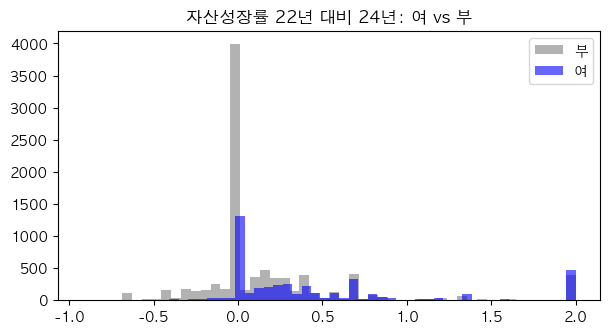

In [8]:
grow = df[df["성장여부"] == 1]
nogrow = df[df["성장여부"] == 0]

# 매출 성장률
print("매출 증가 비율  여:", (grow["매출성장률_22_24"] > 0).mean().round(2), " 부:", (nogrow["매출성장률_22_24"] > 0).mean().round(2))

# 자산 성장률
print("자산 증가 비율  여:", (grow["자산성장률_22_24"] > 0).mean().round(2), " 부:", (nogrow["자산성장률_22_24"] > 0).mean().round(2))

plt.figure(figsize=(7, 3.5))
plt.hist(nogrow["자산성장률_22_24"].clip(-1, 2), bins=50, alpha=0.6, color="gray", label="부")
plt.hist(grow["자산성장률_22_24"].clip(-1, 2), bins=50, alpha=0.6, color="blue", label="여")
plt.legend()
plt.title("자산성장률 22년 대비 24년: 여 vs 부")
plt.show()

In [9]:
df.to_csv("../data/clean.csv", index=False, encoding="utf-8-sig")
print(df.shape)

(13389, 64)
